# Preventing leakage between training and validation

Purging keeps only training observations whose label intervals do not meet any test-label interval:

$$
T_k^{\mathrm{purge}}
=\left\{i\in T_k:
I_i\cap\left(\bigcup_{j\in S_k}I_j\right)=\varnothing\right\}.
$$

Here, $T_k$ is the original training set; $S_k$ is the test set; $I_i$ and $I_j$ are label information intervals. $T_k^{\mathrm{purge}}$ is the retained training set; $k$ indexes folds; $\varnothing$ denotes an empty intersection.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("16_temporal_cross_validation");
using CSV, TOML, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookLogisticLBFGS.jl"))
using RiskLabAI.Validation: KFoldCV,PurgedKFoldCV,WalkForwardCV,cv_split,backtest_predictions,filtered_training_indices_with_embargo
prefix = "embargo"
raw = load_binance()
raw.interval = floor.(raw.time,Minute(15))

function compensated_sum(values)
    total,correction = 0.,0.
    for value in values
        adjusted = value-correction
        updated = total+adjusted
        correction = updated-total-adjusted
        total = updated
    end
    return total
end

bars = combine(groupby(raw,:interval;sort=true),:close=>last=>:Close,:volume=>compensated_sum=>:Volume,:quote_volume=>compensated_sum=>Symbol("Quote volume"),:trades=>compensated_sum=>:Trades)
levels = log.(bars.Close)
returns = vcat(NaN,diff(levels))
positions = collect(18:nrow(bars)-8)
feature_names = ["Previous return","One-hour return","Past volatility","Log volume change","Log quote-volume change","Log trade-count change"]
public_x = hcat(returns[positions.-1],levels[positions.-1].-levels[positions.-5],[std(returns[index-16:index-1]) for index in positions],diff(log1p.(bars.Volume))[positions.-2],diff(log1p.(bars[!,"Quote volume"]))[positions.-2],diff(log1p.(bars.Trades))[positions.-2])
dates,event_times = bars.interval[positions],bars.interval[positions.+8]
forward_returns = levels[positions.+8].-levels[positions]
public_y = Int.(forward_returns.>0)
count_observations = length(public_y)
feature_frame = DataFrame(position=collect(1:count_observations),bar_position=positions,date=dates,end_time=event_times,forward_return=forward_returns,target=public_y)
for (column,name) in enumerate(feature_names)
    feature_frame[!,name] = public_x[:,column]
end
save_data(feature_frame,paths,prefix*"_features")
save_data(bars,paths,prefix*"_bars")
input_root = joinpath("..","data","chapter16_random_inputs")
manifest_path = joinpath(input_root,"inputs.toml")
primitive = TOML.parsefile(manifest_path)["random_fold_permutation"]
permutation_path = joinpath(input_root,primitive["file"])
permutation = CSV.read(permutation_path,DataFrame).position
@assert sort(permutation)==collect(1:count_observations)
@assert nrow(bars)==2976 && size(public_x)==(2951,6)
@assert all(isfinite,public_x) && length(dates)==length(event_times)==length(public_y)
violet = "#C084FC"
split_colors = [palette.grid,palette.cyan,palette.rose,palette.amber,violet]
format_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")

function table(frame,name,caption)
    save_table(frame,paths,name;caption,label="tab:chapter14-"*replace(name,"_"=>"-"))
end

function save_splits(key,splits)
    evidence = DataFrame(fold=Int[],role=String[],order=Int[],position=Int[])
    for (fold,(train,test)) in enumerate(splits), (role,indices) in [("train",train),("test",test)]
        append!(evidence,DataFrame(fold=fill(fold,length(indices)),role=fill(role,length(indices)),order=collect(eachindex(indices)),position=indices))
    end
    save_data(evidence,paths,key*"_splits")
    return nothing
end

function overlap_count(train,test)
    allowed = Set(filtered_training_indices_with_embargo(dates,event_times,test;embargo=0.,continuous=false))
    return count(index->index∉allowed,train)
end

function split_matrix(splits)
    result = zeros(Int,length(splits),count_observations)
    for (fold,(train,test)) in enumerate(splits)
        result[fold,train] .= 1
        result[fold,test] .= 2
    end
    return result
end

function split_legend!(figure;full=false)
    labels = ["Excluded","Train","Test","Overlap removed","Embargo removed"]
    for index in 1:(full ? 5 : 3)
        plot!(figure,[NaN],[NaN];color=split_colors[index],marker=:rect,linewidth=3,label=labels[index])
    end
    plot!(figure;legend=:outerright,colorbar=false)
    return figure
end

function geometry(collections,title_text,stem)
    panels = []
    for (name,splits) in collections
        values = split_matrix(splits)
        panel = heatmap(1:count_observations,1:length(splits),values;color=cgrad(split_colors[1:3],categorical=true),clims=(-.5,2.5),colorbar=false,yflip=true,yticks=1:length(splits),ylabel="Fold",title=name,grid=false,xlims=(.5,count_observations+.5))
        push!(panels,split_legend!(panel))
    end
    plot!(panels[end];xlabel="Observation in time order")
    figure = plot(panels...;layout=(length(panels),1),size=(1300,820),plot_title=title_text,plot_titlefontsize=13,left_margin=8Plots.mm,right_margin=16Plots.mm)
    save_figure(figure,paths,stem)
    return nothing
end

function fitted_model!(records,fold,x,y;weights=ones(length(y)))
    model = BookLogisticLBFGS.fit_logistic(x,y;sample_weight=weights,C=1.,class_weight=nothing,standardize=false,tol=1e-4,max_iter=1000)
    @assert model.converged
    b = model.coefficients
    push!(records,(fold=fold,training_observations=length(y),intercept=model.intercept,b1=b[1],b2=b[2],b3=b[3],b4=b[4],b5=b[5],b6=b[6],objective=model.objective,gradient_norm=model.gradient_norm,iterations=model.iterations,converged=model.converged))
    return model
end

function score_splits(name,splits,key)
    predictions,scores = fill(NaN,count_observations),fill(NaN,count_observations)
    records,models = NamedTuple[],NamedTuple[]
    for (fold,(train,test)) in enumerate(splits)
        accuracy = NaN
        if !isempty(train) && length(unique(public_y[train]))==2
            model = fitted_model!(models,fold,public_x[train,:],public_y[train])
            predictions[test] = BookEstimators.predict(model,public_x[test,:])
            scores[test] = BookEstimators.decision_function(model,public_x[test,:])
            accuracy = mean(predictions[test].==public_y[test])
        end
        push!(records,(method=name,fold=fold,training=length(train),test=length(test),accuracy=accuracy))
    end
    result = DataFrame(records)
    rename!(result,["Method","Fold","Training observations","Test observations","Accuracy"])
    save_splits(key,splits)
    save_data(DataFrame(models),paths,key*"_fits")
    save_data(DataFrame(position=collect(1:count_observations),date=dates,actual=public_y,prediction=predictions,score=scores),paths,key*"_predictions")
    save_data(result,paths,key*"_fold_scores")
    return result,predictions
end

function score_summary(frame;with_count=false)
    records = NamedTuple[]
    for name in unique(frame.Method)
        values = filter(isfinite,frame[frame.Method.==name,"Accuracy"])
        push!(records,(method=name,count=length(values),mean=mean(values),spread=std(values),minimum=minimum(values),maximum=maximum(values)))
    end
    result = DataFrame(records)
    rename!(result,["Method","Scored folds","Mean accuracy","Accuracy spread","Minimum accuracy","Maximum accuracy"])
    return with_count ? result : select(result,Not("Scored folds"))
end


score_summary (generic function with 1 method)

## Purged Fold Anatomy

Row,Fold,Original training observations,Removed by overlap,Removed by embargo,Final training observations,Test observations
,Int64,Int64,Int64,Int64,Int64,Int64
1,1,2459,8,29,2422,492
2,2,2459,16,29,2414,492
3,3,2459,16,29,2414,492
4,4,2459,16,29,2414,492
5,5,2459,16,29,2414,492
6,6,2460,8,0,2452,491


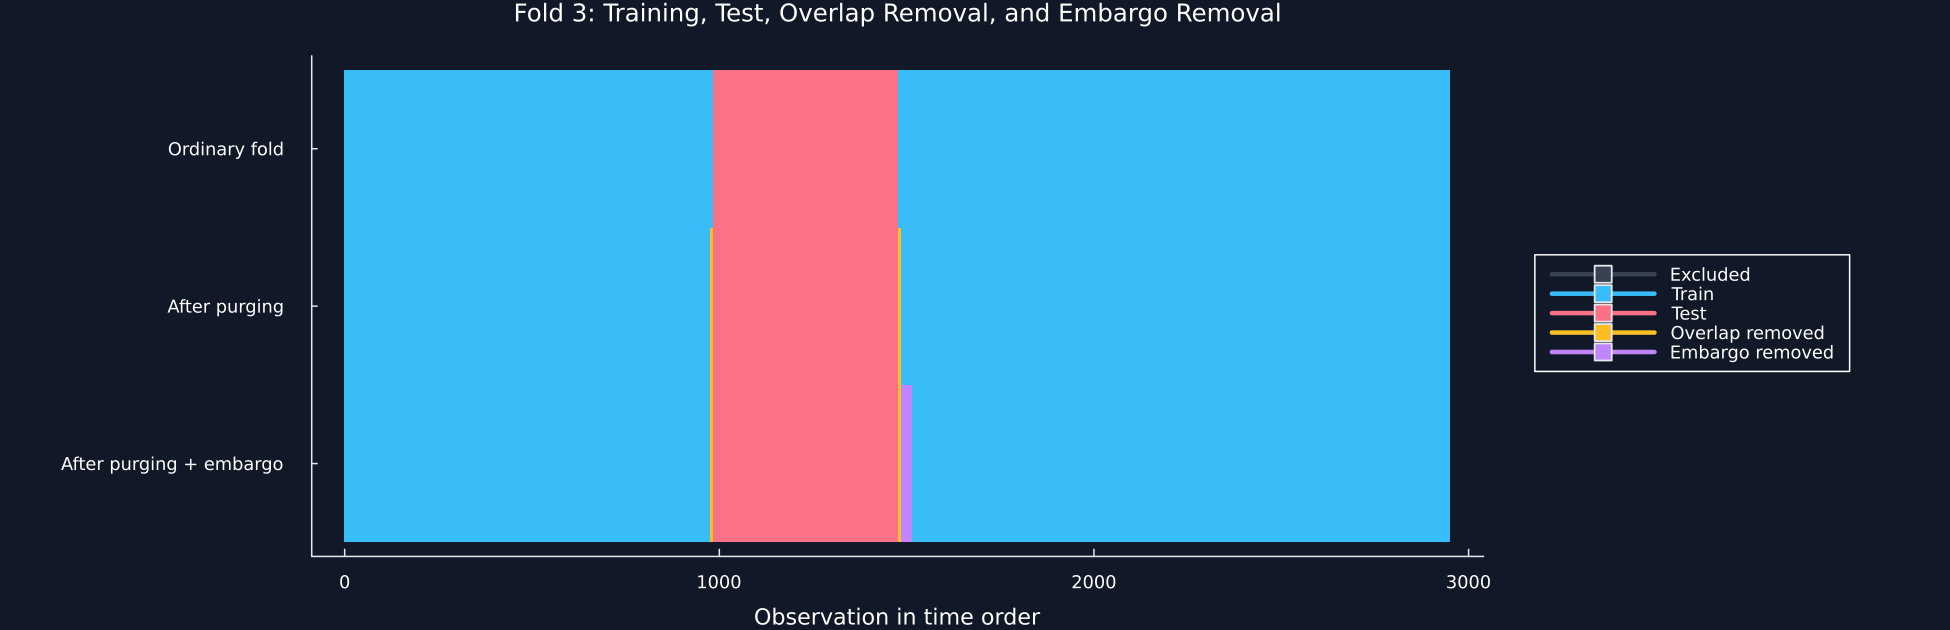

In [2]:
n_splits,embargo_fraction = 6,.01
ordinary_splits = cv_split(KFoldCV(n_splits),count_observations)
no_embargo_splits = cv_split(PurgedKFoldCV(n_splits,dates,event_times;embargo=0.))
embargo_splits = cv_split(PurgedKFoldCV(n_splits,dates,event_times;embargo=embargo_fraction))
fold_size_records = NamedTuple[]
for (fold,((ordinary,test),(purged,_),(embargo,_))) in enumerate(zip(ordinary_splits,no_embargo_splits,embargo_splits))
    push!(fold_size_records,(fold=fold,original=length(ordinary),overlap=length(setdiff(ordinary,purged)),embargo=length(setdiff(purged,embargo)),final=length(embargo),test=length(test)))
end
purging_fold_sizes = DataFrame(fold_size_records)
rename!(purging_fold_sizes,["Fold","Original training observations","Removed by overlap","Removed by embargo","Final training observations","Test observations"])
table(purging_fold_sizes,"purging_fold_sizes","Training observations removed by label overlap and a one-percent embargo.")
save_splits("embargo_ordinary",ordinary_splits)
save_splits("embargo_zero",no_embargo_splits)
save_splits("embargo_one_percent",embargo_splits)
selected_fold = 3
ordinary_train,test = ordinary_splits[selected_fold]
purged_train,_ = no_embargo_splits[selected_fold]
embargo_train,_ = embargo_splits[selected_fold]
anatomy = zeros(Int,3,count_observations)
anatomy[1,ordinary_train] .= 1
anatomy[2,ordinary_train] .= 3
anatomy[2,purged_train] .= 1
anatomy[3,ordinary_train] .= 3
anatomy[3,purged_train] .= 4
anatomy[3,embargo_train] .= 1
anatomy[:,test] .= 2
save_data(DataFrame(position=collect(1:count_observations),ordinary=anatomy[1,:],purged=anatomy[2,:],embargo=anatomy[3,:]),paths,"purging_embargo_anatomy")
figure = heatmap(1:count_observations,1:3,anatomy;color=cgrad(split_colors,categorical=true),clims=(-.5,4.5),colorbar=false,yflip=true,yticks=(1:3,["Ordinary fold","After purging","After purging + embargo"]),xlabel="Observation in time order",title="Fold 3: Training, Test, Overlap Removal, and Embargo Removal",size=(1300,420),grid=false,left_margin=9Plots.mm,right_margin=15Plots.mm)
split_legend!(figure;full=true)
save_figure(figure,paths,"purging_embargo_anatomy")


The embargo adds a declared number of observations after the test information ends before later training observations may be kept:

$$
m=\lfloor \varepsilon n\rfloor,
\qquad
\widetilde I(S_k;\varepsilon)
=\left[\min_{j\in S_k}s_j,\ e_{q_k+m}\right].
$$

Here, $\varepsilon$ is the embargo fraction; $n$ is the sample size; $m$ is the embargo length rounded down. $S_k$ is test fold $k$; $s_j$ is a label start; $q_k$ locates the last test-information end; $e_{q_k+m}$ is the extended end; $\widetilde I$ is the protected interval.

## Testing leakage control across horizon and embargo choices

Row,Label horizon in bars,Embargo fraction,Mean removed observations,Largest removed share
,Int64,Float64,Float64,Float64
1,1,0.0,1.66667,0.000822368
2,1,0.005,13.3333,0.00657895
3,1,0.01,25.8333,0.0127467
4,1,0.02,50.0,0.0246711
5,4,0.0,6.66667,0.00328947
6,4,0.005,18.3333,0.00904605
7,4,0.01,30.8333,0.0152138
8,4,0.02,55.0,0.0271382
9,8,0.0,13.3333,0.00657895


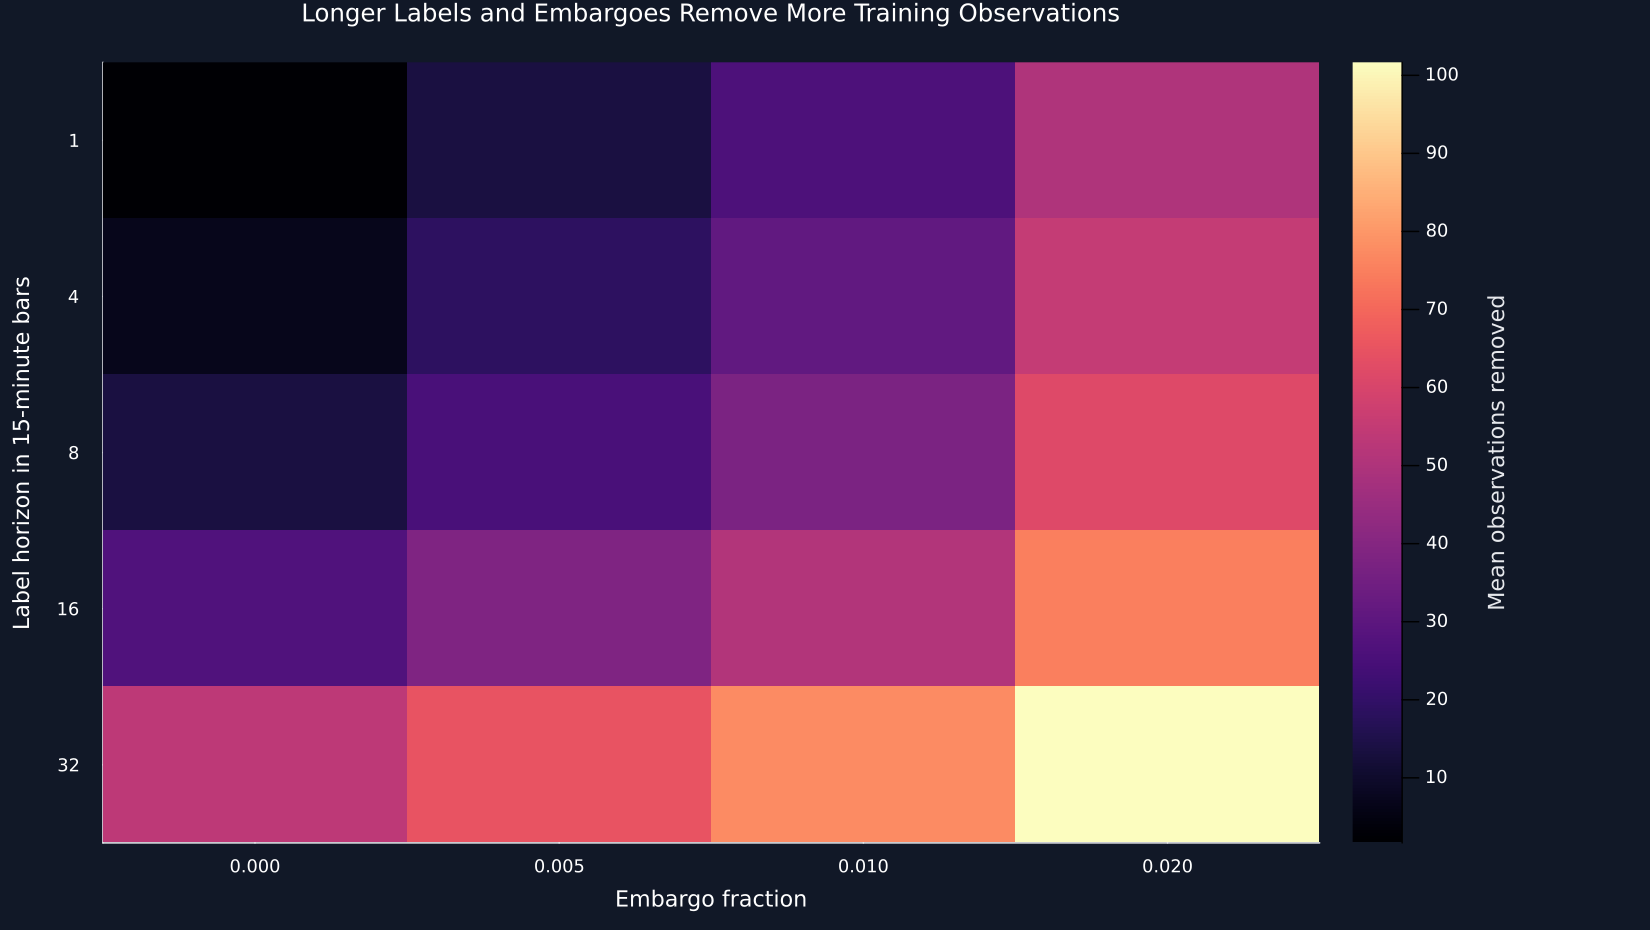

In [3]:
common_length = count_observations-32
common_dates = dates[1:common_length]
sensitivity_records = NamedTuple[]
for horizon in [1,4,8,16,32]
    ends = dates[(1:common_length).+horizon]
    ordinary = cv_split(KFoldCV(n_splits),common_length)
    for (embargo_index,embargo) in enumerate([0.,.005,.01,.02])
        current = cv_split(PurgedKFoldCV(n_splits,common_dates,ends;embargo))
        removals = [length(base_train)-length(clean_train) for ((base_train,_),(clean_train,_)) in zip(ordinary,current)]
        push!(sensitivity_records,(horizon=horizon,embargo=embargo,removed=mean(removals),share=maximum(removals)/length(ordinary[1][1])))
        save_splits("sensitivity_h"*string(horizon)*"_e"*string(embargo_index),current)
    end
end
horizon_embargo_sensitivity = DataFrame(sensitivity_records)
rename!(horizon_embargo_sensitivity,["Label horizon in bars","Embargo fraction","Mean removed observations","Largest removed share"])
table(horizon_embargo_sensitivity,"horizon_embargo_sensitivity","Sensitivity of training-set removal to label horizon and embargo fraction.")
values = permutedims(reshape(horizon_embargo_sensitivity[!,"Mean removed observations"],4,5))
figure = heatmap(1:4,1:5,values;color=:magma,yflip=true,xticks=(1:4,["0.000","0.005","0.010","0.020"]),yticks=(1:5,string.([1,4,8,16,32])),xlabel="Embargo fraction",ylabel="Label horizon in 15-minute bars",colorbar_title="Mean observations removed",title="Longer Labels and Embargoes Remove More Training Observations",size=(1100,620),grid=false,right_margin=22Plots.mm)
save_figure(figure,paths,"horizon_embargo_sensitivity")


Every stored prediction comes from the fit whose training set excludes and protects the fold containing that observation:

$$
\widehat y_i
=\widehat f^{(-k(i))}(x_i),
\qquad i\in S_{k(i)}.
$$

Here, $i$ indexes observations; $k(i)$ is the fold containing $i$; $S_{k(i)}$ is that test fold. $x_i$ is the feature vector; $\widehat f^{(-k(i))}$ is the fold-specific fitted rule; $\widehat y_i$ is the held-out prediction.

## Comparing manual predictions with library output

In [4]:
validator = PurgedKFoldCV(n_splits,dates,event_times;embargo=embargo_fraction)
_,manual_predictions = score_splits("Manual fold loop",cv_split(validator),"embargo_manual")
collected_models = NamedTuple[]
fit_number = Ref(0)
fit_callback = (_,x,y,weights)->begin
    @assert all(==(1.),weights)
    fit_number[] += 1
    fitted_model!(collected_models,fit_number[],x,y;weights)
end
collected_predictions = backtest_predictions(validator,nothing,public_x,public_y;clone_estimator=identity,fit_estimator=fit_callback,predict=BookEstimators.predict)[1]
save_data(DataFrame(collected_models),paths,"embargo_collected_fits")
save_data(DataFrame(position=collect(1:count_observations),prediction=collected_predictions),paths,"embargo_collected_predictions")
path_records = NamedTuple[]
for (fold,(train,test)) in enumerate(cv_split(validator))
    push!(path_records,(fold=fold,training=length(train),test=length(test),first_train=format_time(dates[first(train)]),last_train=format_time(dates[last(train)]),first_test=format_time(dates[first(test)]),last_test=format_time(dates[last(test)])))
end
purged_path_summary = DataFrame(path_records)
rename!(purged_path_summary,["Fold","Training observations","Test observations","First training time","Last training time","First test time","Last test time"])
table(purged_path_summary,"purged_path_summary","Time ranges and sizes for the six purged public-data folds.")
prediction_check = DataFrame("Calculation"=>["Manual fold loop","Collected fold predictions"],"Predictions"=>[count(isfinite,manual_predictions),count(isfinite,collected_predictions)],"Accuracy"=>[mean(public_y.==manual_predictions),mean(public_y.==collected_predictions)],"Agreement with manual calculation"=>[1.,mean(collected_predictions.==manual_predictions)])
table(prediction_check,"prediction_equivalence","Independent and collected purged-fold predictions on the public data.")


Row,Fold,Training observations,Test observations,First training time,Last training time,First test time,Last test time
,Int64,Int64,Int64,String,String,String,String
1,1,2422,492,2021-01-06 16:30:00,2021-01-31 21:45:00,2021-01-01 04:15:00,2021-01-06 07:00:00
2,2,2414,492,2021-01-01 04:15:00,2021-01-31 21:45:00,2021-01-06 07:15:00,2021-01-11 10:00:00
3,3,2414,492,2021-01-01 04:15:00,2021-01-31 21:45:00,2021-01-11 10:15:00,2021-01-16 13:00:00
4,4,2414,492,2021-01-01 04:15:00,2021-01-31 21:45:00,2021-01-16 13:15:00,2021-01-21 16:00:00
5,5,2414,492,2021-01-01 04:15:00,2021-01-31 21:45:00,2021-01-21 16:15:00,2021-01-26 19:00:00
6,6,2452,491,2021-01-01 04:15:00,2021-01-26 17:00:00,2021-01-26 19:15:00,2021-01-31 21:45:00


Row,Calculation,Predictions,Accuracy,Agreement with manual calculation
,String,Int64,Float64,Float64
1,Manual fold loop,2951,0.489326,1.0
2,Collected fold predictions,2951,0.489326,1.0


## Tests

In [5]:
@assert size(purging_fold_sizes)==(6,6)
@assert all(>(0),purging_fold_sizes[!,"Removed by overlap"])
@assert all(>=(0),purging_fold_sizes[!,"Removed by embargo"])
@assert all(purging_fold_sizes[!,"Final training observations"].<purging_fold_sizes[!,"Original training observations"])
@assert size(horizon_embargo_sensitivity)==(20,4)
@assert all(>=(0),horizon_embargo_sensitivity[!,"Mean removed observations"])
@assert issorted([mean(horizon_embargo_sensitivity[horizon_embargo_sensitivity[!,"Embargo fraction"].==value,"Mean removed observations"]) for value in [0.,.005,.01,.02]])
@assert issorted([mean(horizon_embargo_sensitivity[horizon_embargo_sensitivity[!,"Label horizon in bars"].==value,"Mean removed observations"]) for value in [1,4,8,16,32]])
@assert manual_predictions==collected_predictions
@assert all(value->0<=value<=1,prediction_check.Accuracy)
@assert size(purged_path_summary)==(6,7)
@assert isfile(joinpath(paths.figures,"purging_embargo_anatomy.pdf"))
@assert isfile(joinpath(paths.figures,"horizon_embargo_sensitivity.pdf"))
@assert isfile(joinpath(paths.tables,"purging_fold_sizes.tex"))
@assert isfile(joinpath(paths.tables,"horizon_embargo_sensitivity.tex"))
@assert isfile(joinpath(paths.tables,"purged_path_summary.tex"))
@assert isfile(joinpath(paths.tables,"prediction_equivalence.tex"))
